# Практическое занятие 3

**Задание:** по квартальным данным потребления электроэнергии за 2018–2021 гг. исследовать структуру временного ряда и оценить уровень и структуру потребления электроэнергии в 2022 г.

## Этап 1. Ввод исходных данных

Сначала занесём в таблицу значения из задания.  
Переменная t — порядковый номер квартала: от 1 до 16.

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Данные из задания
data = {
    "Год": [2018]*4 + [2019]*4 + [2020]*4 + [2021]*4,
    "Квартал": ["I", "II", "III", "IV"]*4,
    "Потребление": [
        6.0, 4.4, 5.0, 9.0,
        7.2, 4.8, 6.0, 10.0,
        8.0, 5.6, 6.4, 11.0,
        9.0, 6.6, 7.0, 10.8
    ]
}

df = pd.DataFrame(data)
df["t"] = np.arange(1, len(df) + 1)

df

,Год,Квартал,Потребление,t
0,2018,I,6.0,1
1,2018,II,4.4,2
2,2018,III,5.0,3
3,2018,IV,9.0,4
4,2019,I,7.2,5
5,2019,II,4.8,6
6,2019,III,6.0,7
7,2019,IV,10.0,8
8,2020,I,8.0,9
9,2020,II,5.6,10


## Этап 2. Посмотрим на временной ряд

По графику можно увидеть общую тенденцию изменения потребления и повторяющиеся квартальные колебания.  
Если колебания примерно повторяются через одинаковые промежутки времени, это признак сезонности.

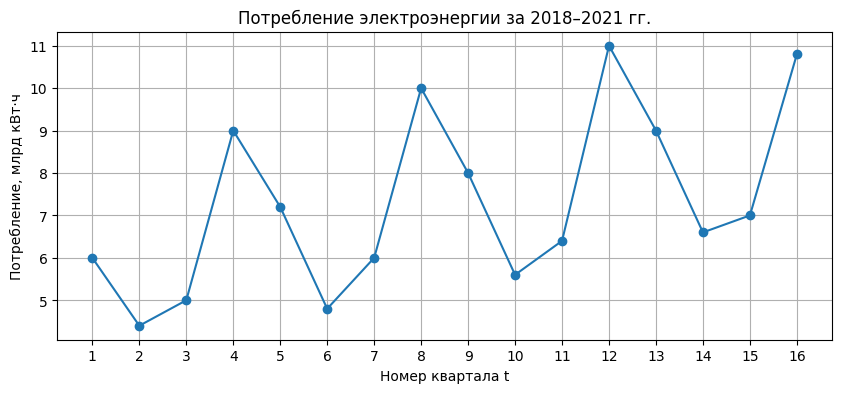

In [16]:
plt.figure(figsize=(10, 4))
plt.plot(df["t"], df["Потребление"], marker="o")
plt.xticks(df["t"])
plt.xlabel("Номер квартала t")
plt.ylabel("Потребление, млрд кВт·ч")
plt.title("Потребление электроэнергии за 2018–2021 гг.")
plt.grid()
plt.show()

## Этап 3. Оценка линейного тренда методом наименьших квадратов

В лекции 3 для линейного тренда используется модель

\[
\tilde y_t = a_0 + a_1t.
\]

Коэффициенты можно найти методом наименьших квадратов. В удобной форме:

\[
a_1=\frac{\sum (t-\bar t)(y-\bar y)}
{\sum (t-\bar t)^2},
\qquad
a_0=\bar y-a_1\bar t.
\]

Коэффициент \(a_1\) показывает, насколько в среднем меняется уровень ряда за один квартал.

In [17]:
t = df["t"].to_numpy()
y = df["Потребление"].to_numpy()

t_mean = t.mean()
y_mean = y.mean()

# Коэффициенты линейного тренда по МНК
a1 = np.sum((t - t_mean) * (y - y_mean)) / np.sum((t - t_mean) ** 2)
a0 = y_mean - a1 * t_mean

df["Тренд"] = a0 + a1 * df["t"]

print(f"a0 = {a0:.4f}")
print(f"a1 = {a1:.4f}")
print(f"Уравнение тренда: y = {a0:.4f} + {a1:.4f} * t")

a0 = 5.3650
a1 = 0.2276
Уравнение тренда: y = 5.3650 + 0.2276 * t


### Сравнение фактического ряда и тренда

Добавим на график линию тренда. Она показывает общее направление изменения ряда без квартальной сезонности.

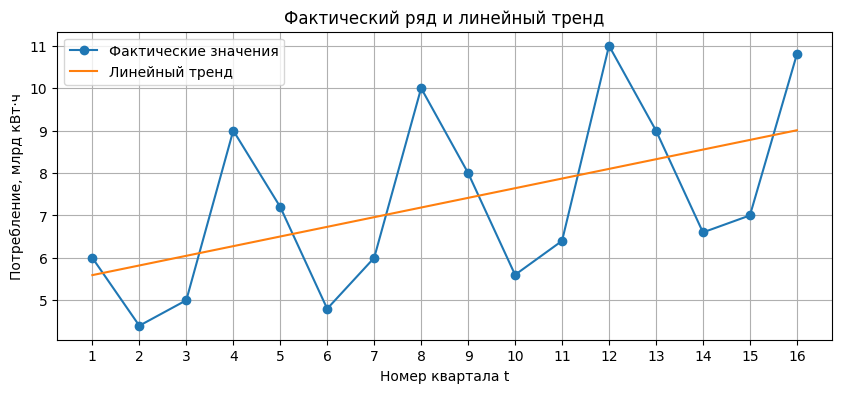

In [18]:
plt.figure(figsize=(10, 4))
plt.plot(df["t"], df["Потребление"], marker="o", label="Фактические значения")
plt.plot(df["t"], df["Тренд"], label="Линейный тренд")
plt.xticks(df["t"])
plt.xlabel("Номер квартала t")
plt.ylabel("Потребление, млрд кВт·ч")
plt.title("Фактический ряд и линейный тренд")
plt.grid()
plt.legend()
plt.show()

## Этап 4. Оценка сезонной структуры ряда

Чтобы учесть различия между кварталами, найдём **сезонные индексы**.

Сначала для каждого наблюдения вычислим отношение фактического значения к тренду:

\[
S_t=\frac{y_t}{\tilde y_t}.
\]

Затем усредним эти отношения отдельно для I, II, III и IV кварталов.  
После этого нормируем индексы так, чтобы их среднее было равно 1.

Интерпретация простая:

- индекс больше 1 — квартал обычно выше уровня тренда;
- индекс меньше 1 — квартал обычно ниже уровня тренда.

In [19]:
# Отношение фактических значений к тренду
df["Отношение к тренду"] = df["Потребление"] / df["Тренд"]

# Среднее отношение для каждого квартала
season = df.groupby("Квартал", sort=False)["Отношение к тренду"].mean()

# Нормировка: среднее сезонных индексов должно быть равно 1
season = season / season.mean()

season_table = pd.DataFrame({
    "Квартал": season.index,
    "Сезонный индекс": season.values,
    "Отклонение от тренда, %": (season.values - 1) * 100
})

season_table.round(3)

,Квартал,Сезонный индекс,"Отклонение от тренда, %"
0,I,1.085,8.527
1,II,0.744,-25.643
2,III,0.825,-17.494
3,IV,1.346,34.609


### График сезонных индексов

Значение 1 соответствует обычному уровню тренда. Чем выше столбец относительно 1, тем выше сезонное потребление в этом квартале.

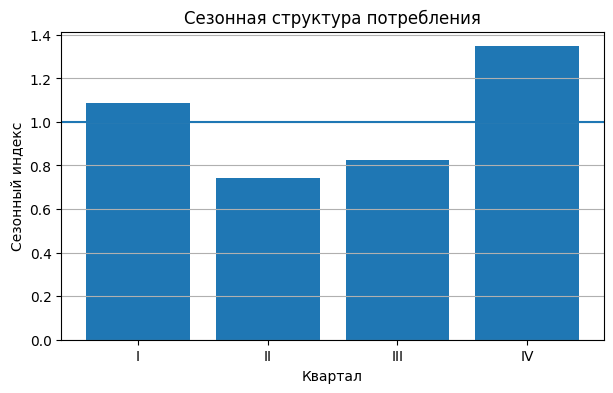

In [20]:
plt.figure(figsize=(7, 4))
plt.bar(season_table["Квартал"], season_table["Сезонный индекс"])
plt.axhline(1)
plt.xlabel("Квартал")
plt.ylabel("Сезонный индекс")
plt.title("Сезонная структура потребления")
plt.grid(axis="y")
plt.show()

## Этап 5. Построение модели и оценка точности

Будем использовать простую модель

\[
\hat y_t = T_t \cdot S_q,
\]

где \(T_t\) — значение линейного тренда, а \(S_q\) — сезонный индекс соответствующего квартала.

Остаток:

\[
\varepsilon_t = y_t-\hat y_t.
\]

Для оценки точности используем среднюю относительную ошибку аппроксимации:

\[
E_{\text{отн}}=
\frac{1}{n}\sum_{t=1}^{n}
\left|\frac{\varepsilon_t}{y_t}\right|\cdot100\%.
\]

В лекции 3 указано, что при ошибке не более 15% точность модели считается приемлемой.

In [21]:
# Добавляем сезонный индекс каждой строке
df["Сезонный индекс"] = df["Квартал"].map(season)

# Расчетные значения модели
df["Расчетное значение"] = df["Тренд"] * df["Сезонный индекс"]
df["Остаток"] = df["Потребление"] - df["Расчетное значение"]

# Средняя относительная ошибка
mape = np.mean(np.abs(df["Остаток"] / df["Потребление"])) * 100

result_table = df[
    ["Год", "Квартал", "Потребление", "Тренд",
     "Сезонный индекс", "Расчетное значение", "Остаток"]
]

display(result_table.round(3))

print(f"Средняя относительная ошибка = {mape:.2f}%")

if mape <= 15:
    print("Ошибка меньше 15%, точность модели приемлемая.")
else:
    print("Ошибка больше 15%, точность модели недостаточная.")

,Год,Квартал,Потребление,Тренд,Сезонный индекс,Расчетное значение,Остаток
0,2018,I,6.0,5.593,1.085,6.070,-0.070
1,2018,II,4.4,5.820,0.744,4.328,0.072
2,2018,III,5.0,6.048,0.825,4.990,0.010
3,2018,IV,9.0,6.276,1.346,8.448,0.552
4,2019,I,7.2,6.503,1.085,7.058,0.142
5,2019,II,4.8,6.731,0.744,5.005,-0.205
6,2019,III,6.0,6.959,0.825,5.741,0.259
7,2019,IV,10.0,7.186,1.346,9.673,0.327
8,2020,I,8.0,7.414,1.085,8.046,-0.046
9,2020,II,5.6,7.641,0.744,5.682,-0.082


Средняя относительная ошибка = 2.95%
Ошибка меньше 15%, точность модели приемлемая.


### Фактические и расчётные значения

Если линии расположены близко друг к другу, модель хорошо описывает исходный ряд.

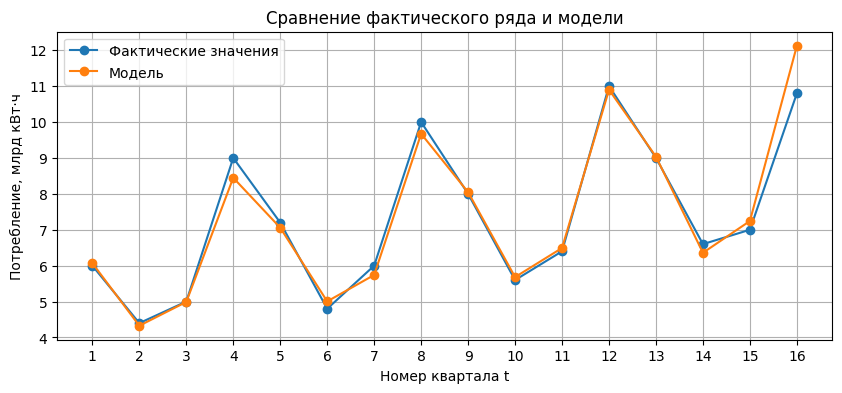

In [22]:
plt.figure(figsize=(10, 4))
plt.plot(df["t"], df["Потребление"], marker="o", label="Фактические значения")
plt.plot(df["t"], df["Расчетное значение"], marker="o", label="Модель")
plt.xticks(df["t"])
plt.xlabel("Номер квартала t")
plt.ylabel("Потребление, млрд кВт·ч")
plt.title("Сравнение фактического ряда и модели")
plt.grid()
plt.legend()
plt.show()

## Этап 6. Оценка уровня и структуры потребления в 2022 году

В лекции 3 точечный прогноз получают экстраполяцией тренда: в модель подставляют будущие значения времени.

Для 2022 года это \(t=17,18,19,20\).

Так как в нашем ряду есть квартальная сезонность, прогноз для каждого квартала получим так:

\[
\hat y_{2022,q}=T_{2022,q}\cdot S_q.
\]

После этого найдём общий объём потребления за 2022 год и долю каждого квартала в годовом объёме.

In [23]:
forecast = pd.DataFrame({
    "Год": [2022] * 4,
    "Квартал": ["I", "II", "III", "IV"],
    "t": [17, 18, 19, 20]
})

# Продолжаем линейный тренд на 2022 год
forecast["Тренд"] = a0 + a1 * forecast["t"]

# Учитываем сезонность кварталов
forecast["Сезонный индекс"] = forecast["Квартал"].map(season)
forecast["Прогноз"] = forecast["Тренд"] * forecast["Сезонный индекс"]

# Структура годового потребления по кварталам
year_total = forecast["Прогноз"].sum()
forecast["Доля в годовом объеме, %"] = forecast["Прогноз"] / year_total * 100

display(forecast.round({
    "Тренд": 3,
    "Сезонный индекс": 3,
    "Прогноз": 3,
    "Доля в годовом объеме, %": 1
}))

print(f"Прогноз потребления за весь 2022 год: {year_total:.2f} млрд кВт·ч")
print(f"Среднее потребление за квартал: {forecast['Прогноз'].mean():.2f} млрд кВт·ч")

,Год,Квартал,t,Тренд,Сезонный индекс,Прогноз,"Доля в годовом объеме, %"
0,2022,I,17,9.235,1.085,10.022,26.1
1,2022,II,18,9.463,0.744,7.036,18.3
2,2022,III,19,9.690,0.825,7.995,20.8
3,2022,IV,20,9.918,1.346,13.350,34.8


Прогноз потребления за весь 2022 год: 38.40 млрд кВт·ч
Среднее потребление за квартал: 9.60 млрд кВт·ч


### Прогноз по кварталам на 2022 год

Покажем итоговые квартальные значения на графике.

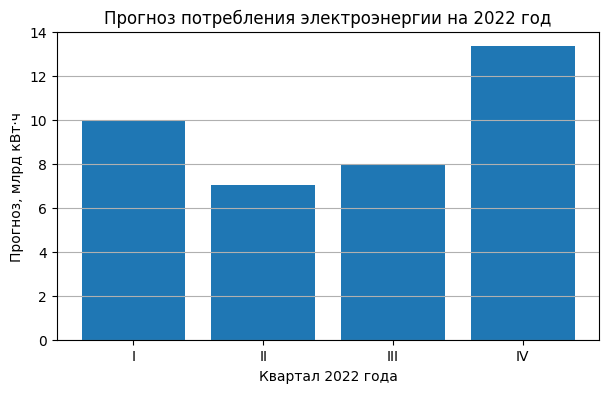

In [24]:
plt.figure(figsize=(7, 4))
plt.bar(forecast["Квартал"], forecast["Прогноз"])
plt.xlabel("Квартал 2022 года")
plt.ylabel("Прогноз, млрд кВт·ч")
plt.title("Прогноз потребления электроэнергии на 2022 год")
plt.grid(axis="y")
plt.show()

## Вывод

1. В ряду есть **положительный линейный тренд**: по модели потребление увеличивается примерно на **0,228 млрд кВт·ч за квартал**.
2. Есть выраженная **квартальная сезонность**. Самый высокий сезонный уровень наблюдается в IV квартале, самый низкий — во II квартале.
3. Средняя относительная ошибка построенной модели составляет примерно **2,95%**, что меньше 15%.
4. Прогноз общего потребления электроэнергии в **2022 году — около 38,40 млрд кВт·ч**.
5. Прогноз по кварталам:
   - I квартал — **10,02 млрд кВт·ч**;
   - II квартал — **7,04 млрд кВт·ч**;
   - III квартал — **8,00 млрд кВт·ч**;
   - IV квартал — **13,35 млрд кВт·ч**.
6. Ожидаемая структура годового потребления: около **26,1%**, **18,3%**, **20,8%** и **34,8%** соответственно по кварталам.